# 02 · Train and evaluate Sentinel-1 LULC segmentation models (dataset v3)

**Classes:** Forest, Grassland (incl. shrubland and herbaceous wetland), Cropland, Urban, Water.

**Setup**
- Encoder pretrained on ImageNet (transfer learning; `segmentation_models_pytorch` adapts the first convolution to the number of SAR channels).
- Loss: 0.5 · class-weighted cross-entropy + 0.5 · Dice. Weights are 1/√frequency, so the rare water class is not ignored without overweighting it. Unlabelled pixels (255) are ignored.
- Optimiser: AdamW, one-cycle learning rate (10 % warm-up, then cosine decay to ~0) over the full 40 epochs, gradient clipping, bfloat16 mixed precision. The checkpoint with the best validation mIoU is kept (no early stopping, so the schedule always completes).
- **Multi-year sampling:** one epoch visits every training location-month once, each time in a randomly drawn year (2020–2023). The model sees four different weather/crop years of every place without a 4× longer epoch.
- Augmentation: flips, 90° rotations, ±~1 dB per-channel offset and slight noise (mimics calibration/incidence-angle variation).
- **Labels:** 2021 imagery is scored against the full WorldCover 2021 map, other years against the pixels where WorldCover 2020 and 2021 agree (see `lulc_common.LABEL_YEAR`). The headline metrics use **2021** (same-year labels, all pixels).
- Model selection uses the **validation** set only; test and generalisation sets are evaluated once at the end, with 95 % confidence intervals from a bootstrap over 5.12 km blocks.

**Variants** (each differs from `Unet_ctx` in one thing, so every gain can be attributed):

| Variant | Encoder | Input | Training labels |
|---|---|---|---|
| `Unet_single` | ResNet-34 | current month (5 ch) | WorldCover |
| `Unet_ctx` | ResNet-34 | previous + current + next month (15 ch) | WorldCover |
| `Unet_ctx_smooth` | ResNet-34 | previous + current + next month | 5×5 majority-filtered WorldCover (granularity of ~20 m SAR) |
| `Unet_r50_ctx` | ResNet-50 | previous + current + next month | WorldCover |

Dataset v2 already compared U-Net with DeepLabV3+ (no gain: 69.6 vs 70.5 test mIoU), so v3 spends its
training budget on temporal context, label granularity and encoder size instead.

In [1]:
import random, sys, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd()))
import lulc_common as lc

SEED = 42
EPOCHS = 40          # full one-cycle schedule (no early stopping): the low-LR end phase is where it converges
BATCH_SIZE = 16
MAX_LR = 1e-3
GRAD_CLIP = 1.0
N_BOOTSTRAP = 1000
LOADER_THREADS = 12  # batches are assembled by threads (DataLoader workers need /dev/shm, which is 64 MB on DataLab)

ALL_CH = list(lc.CHANNELS)
VARIANTS = {
    "Unet_single":     dict(arch="Unet", encoder="resnet34", channels=ALL_CH, context=False, smooth_labels=False),
    "Unet_ctx":        dict(arch="Unet", encoder="resnet34", channels=ALL_CH, context=True, smooth_labels=False),
    "Unet_ctx_smooth": dict(arch="Unet", encoder="resnet34", channels=ALL_CH, context=True, smooth_labels=True),
    "Unet_r50_ctx":    dict(arch="Unet", encoder="resnet50", channels=ALL_CH, context=True, smooth_labels=False),
}
# name: (split, imagery years). "2021" sets use same-year labels on all pixels -> headline numbers.
EVAL_SETS = {
    "test 2021":          ("test", [2021]),
    "test 2020–23":       ("test", [2020, 2021, 2022, 2023]),
    "holdout_de 2021":    ("holdout_de", [2021]),
    "holdout_de 2024–25": ("holdout_de", [2024, 2025]),
    "ood 2021":           ("ood", [2021]),
    "ood 2024–25":        ("ood", [2024, 2025]),
}
# Rural regions added in v3. The test blocks of all other regions are identical to dataset v2 (same seeds
# and grids), so "test 2021 (v2 regions)" with merged classes is directly comparable to the v2 results.
RURAL_REGIONS = ["magdeburger_boerde", "uckermark", "allgaeu", "harz", "champagne", "beauce", "normandy_bocage",
                 "friesland", "jutland_heath", "south_bohemia", "mazury_lakes", "hungarian_plain"]


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
# bfloat16 has the float32 exponent range, so logits cannot overflow to inf (float16 produced a NaN
# validation loss). It needs Ampere or newer (A6000/H200); older GPUs fall back to float16 + GradScaler.
amp_dtype = torch.bfloat16 if use_amp and torch.cuda.is_bf16_supported() else torch.float16
lc.MODEL_DIR.mkdir(parents=True, exist_ok=True)
lc.FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", device, torch.cuda.get_device_name(0) if use_amp else "", "| AMP dtype:", amp_dtype)
print("Dataset:", lc.DATA_DIR)

meta = pd.read_csv(lc.DATA_DIR / "patches_meta.csv")
meta["group"] = meta.region + "/" + meta.block            # bootstrap unit: one 5.12 km block
meta["loc"] = meta.region + "/" + meta.y.astype(str) + "/" + meta.x.astype(str)
meta["t"] = meta.year * 12 + meta.month - 1               # running month index
meta.pivot_table(index="split", columns="year", values="image", aggfunc="count", fill_value=0)

Device: cuda NVIDIA RTX A6000 | AMP dtype: torch.bfloat16
Dataset: /home/jovyan/vault/deep_learning/data/v3


year,2020,2021,2022,2023,2024,2025
split,,,,,,
holdout_de,768,768,768,768,768,768
ood,768,768,768,768,768,768
test,4448,4423,4464,4464,0,0
train,14738,14650,14784,14784,0,0
val,2922,2892,2928,2928,0,0


## Load all patches into RAM
~75 GB as float16/uint8 (the DataLab machine has ~180 GB free). Reading ~200k small files from the network
drive once is much faster than reading them every epoch. `PREV`/`NEXT` point to the same location's
previous/next month (across year boundaries), or -1 if that patch does not exist.

In [2]:
N = len(meta)
IMAGES = np.empty((N, len(lc.CHANNELS), 256, 256), dtype=np.float16)
MASKS = np.empty((N, 2, 256, 256), dtype=np.uint8)
YEAR = meta.year.to_numpy()


image_paths, mask_paths = meta["image"].tolist(), meta["mask"].tolist()


def _load(i):
    IMAGES[i] = np.load(lc.DATA_DIR / image_paths[i])
    MASKS[i] = np.load(lc.DATA_DIR / mask_paths[i])


t0 = time.time()
with ThreadPoolExecutor(32) as pool:
    for k, _ in enumerate(pool.map(_load, range(N)), 1):
        if k % 20000 == 0 or k == N:
            print(f"loaded {k}/{N} patches ({time.time() - t0:.0f}s)", flush=True)

index_of = {(l, t): i for i, (l, t) in enumerate(zip(meta["loc"], meta["t"]))}
PREV = np.array([index_of.get((l, t - 1), -1) for l, t in zip(meta["loc"], meta["t"])])
NEXT = np.array([index_of.get((l, t + 1), -1) for l, t in zip(meta["loc"], meta["t"])])
print(f"RAM: {(IMAGES.nbytes + MASKS.nbytes) / 1e9:.1f} GB | patches with previous month: {(PREV >= 0).mean():.1%}, "
      f"next month: {(NEXT >= 0).mean():.1%}")

loaded 20000/97641 patches (23s)
loaded 40000/97641 patches (81s)
loaded 60000/97641 patches (190s)
loaded 80000/97641 patches (335s)
loaded 97641/97641 patches (471s)
RAM: 76.8 GB | patches with previous month: 97.7%, next month: 97.7%


In [3]:
def get_sample(i, cfg, smooth=False):
    """Network input (C, H, W) float32 and target (H, W) int64 for patch i."""
    cur = IMAGES[i].astype(np.float32)
    nb = {}
    if cfg["context"]:
        for name, j in (("prev", PREV[i]), ("nxt", NEXT[i])):
            if j >= 0:
                nb[name] = IMAGES[j].astype(np.float32)
                nb[f"{name}_valid"] = MASKS[j, 0] != 0          # SAR-invalid pixels were stored as code 0
    x = lc.model_input(cfg, cur, nb.get("prev"), nb.get("nxt"), nb.get("prev_valid"), nb.get("nxt_valid"))
    y = lc.labels_from_raw(MASKS[i], year=YEAR[i])
    if smooth:
        y = lc.majority_filter(y)
    return x, y


def _flip_rot(x, y, rng):
    if rng.random() < 0.5:
        x, y = x[:, :, ::-1], y[:, ::-1]
    if rng.random() < 0.5:
        x, y = x[:, ::-1, :], y[::-1, :]
    k = rng.integers(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)


class Batches:
    """Iterates over (x, y) batches assembled by a thread pool.

    items: patch indices, or for training a list of index arrays (one random member drawn per epoch:
    the same location-month in a random year).
    """

    def __init__(self, items, cfg, train=False):
        self.items, self.cfg, self.train = items, cfg, train
        self.smooth = train and cfg.get("smooth_labels", False)
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        n = len(self.items)
        return n // BATCH_SIZE if self.train else -(-n // BATCH_SIZE)

    def _batch(self, chunk, seed):
        rng = np.random.default_rng(seed)
        xs, ys = [], []
        for item in chunk:
            i = rng.choice(item) if self.train else item
            x, y = get_sample(i, self.cfg, self.smooth)
            if self.train:
                x, y = _flip_rot(x, y, rng)
            xs.append(np.ascontiguousarray(x))
            ys.append(np.ascontiguousarray(y))
        return torch.from_numpy(np.stack(xs)), torch.from_numpy(np.stack(ys).astype(np.int64))

    def __iter__(self):
        order = self.rng.permutation(len(self.items)) if self.train else np.arange(len(self.items))
        chunks = [[self.items[j] for j in order[k:k + BATCH_SIZE]] for k in range(0, len(order), BATCH_SIZE)]
        if self.train and len(chunks[-1]) < BATCH_SIZE:
            chunks = chunks[:-1]
        seeds = self.rng.integers(0, 2**31, size=len(chunks))
        with ThreadPoolExecutor(LOADER_THREADS) as pool:
            queue = deque()
            for c, s in zip(chunks, seeds):
                queue.append(pool.submit(self._batch, c, s))
                if len(queue) > 2 * LOADER_THREADS:
                    yield queue.popleft().result()
            while queue:
                yield queue.popleft().result()


def gpu_augment(x):
    """Per-sample, per-channel offset (±0.03 ≈ ±1 dB) and slight noise, on the GPU."""
    x = x + torch.empty(x.shape[0], x.shape[1], 1, 1, device=x.device).uniform_(-0.03, 0.03)
    return (x + 0.01 * torch.randn_like(x)).clamp_(0.0, 1.0)


train_idx = meta.index[meta.split == "train"].to_numpy()
train_groups = list(meta.loc[train_idx].groupby(["loc", "month"]).indices.values())
train_groups = [train_idx[g] for g in train_groups]
val_idx = meta.index[meta.split == "val"].to_numpy()
print(f"training: {len(train_idx)} patches = {len(train_groups)} location-months x up to 4 years | "
      f"validation: {len(val_idx)} patches")

# Class weights from the training labels (1 / sqrt(frequency), mean 1), using each year's label rule.
px = np.zeros(lc.NUM_CLASSES)
for i in np.random.default_rng(SEED).choice(train_idx, min(len(train_idx), 10000), replace=False):
    lab = lc.labels_from_raw(MASKS[i], year=YEAR[i])
    px += np.bincount(lab[lab != lc.IGNORE_INDEX], minlength=lc.NUM_CLASSES)
freq = px / px.sum()
class_weights = 1.0 / np.sqrt(freq)
class_weights = class_weights / class_weights.mean()
pd.DataFrame({"class": lc.CLASS_NAMES, "train pixels (%)": (freq * 100).round(2),
              "loss weight": class_weights.round(3)})

training: 58956 patches = 14784 location-months x up to 4 years | validation: 11670 patches


,class,train pixels (%),loss weight
0,Forest,37.89,0.617
1,Grassland,16.68,0.930
2,Cropland,17.70,0.902
3,Urban,23.09,0.790
4,Water,4.64,1.762


In [4]:
ce_loss = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
                              ignore_index=lc.IGNORE_INDEX)
dice_loss = smp.losses.DiceLoss(mode="multiclass", ignore_index=lc.IGNORE_INDEX)


def criterion(logits, target):
    return 0.5 * ce_loss(logits, target) + 0.5 * dice_loss(logits, target)


@torch.no_grad()
def evaluate(model, batches):
    """Mean loss and pixel confusion matrix (rows = label, cols = prediction)."""
    model.eval()
    n = lc.NUM_CLASSES
    cm = torch.zeros(n * n, dtype=torch.long, device=device)
    total_loss, count = 0.0, 0
    for x, y in batches:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            logits = model(x)
        total_loss += criterion(logits.float(), y).item()
        count += 1
        keep = y != lc.IGNORE_INDEX
        cm += torch.bincount(y[keep] * n + logits.argmax(1)[keep], minlength=n * n)
    return total_loss / max(count, 1), cm.view(n, n).cpu().numpy()


def train_variant(name, cfg):
    seed_everything(SEED)
    train_batches = Batches(train_groups, cfg, train=True)
    val_batches = Batches(val_idx, cfg)
    model = lc.build_model(cfg["arch"], cfg["encoder"], lc.n_input_channels(cfg), encoder_weights="imagenet").to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, pct_start=0.1,
                                                    total_steps=EPOCHS * len(train_batches))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp and amp_dtype == torch.float16)
    ckpt_cfg = {"name": name, **cfg, "class_names": lc.CLASS_NAMES, "db_ranges": lc.DB_RANGES,
                "max_scenes_per_month": lc.MAX_SCENES_PER_MONTH, "dataset": lc.DATASET_VERSION,
                "label_rule": f"{lc.LABEL_YEAR}: full WorldCover {lc.LABEL_YEAR}; other years: 2020/2021-stable pixels",
                "train": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "max_lr": MAX_LR, "seed": SEED,
                          "years": sorted(meta.loc[train_idx, "year"].unique().tolist())}}

    history, best_miou = [], -1.0
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        model.train()
        running = 0.0
        for x, y in train_batches:
            x, y = gpu_augment(x.to(device, non_blocking=True)), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
        val_loss, cm = evaluate(model, val_batches)
        m = lc.metrics_from_confusion(cm)
        history.append({"epoch": epoch, "lr": scheduler.get_last_lr()[0], "train_loss": running / len(train_batches),
                        "val_loss": val_loss, "val_OA": m["OA"], "val_mIoU": m["mIoU"]})
        improved = m["mIoU"] > best_miou
        if improved:
            best_miou = m["mIoU"]
            torch.save({"config": ckpt_cfg, "state_dict": model.state_dict(), "epoch": epoch,
                        "val_mIoU": best_miou}, lc.MODEL_DIR / f"{name}.pth")
        print(f"[{name}] epoch {epoch:02d} | lr {history[-1]['lr']:.1e} | train {history[-1]['train_loss']:.4f} | "
              f"val {val_loss:.4f} | OA {m['OA']:.4f} | mIoU {m['mIoU']:.4f}{' *' if improved else ''} | "
              f"{time.time() - t0:.0f}s", flush=True)
    history = pd.DataFrame(history)
    history.to_csv(lc.FIGURE_DIR / f"history_{name}.csv", index=False)
    return history, best_miou

Training is resumable: a variant whose checkpoint and `figures/v3/history_<name>.csv` already exist is
loaded instead of retrained (delete both files to retrain it).

In [5]:
histories, best_val = {}, {}
for name, cfg in VARIANTS.items():
    hist_path, ckpt_path = lc.FIGURE_DIR / f"history_{name}.csv", lc.MODEL_DIR / f"{name}.pth"
    if hist_path.exists() and ckpt_path.exists():
        histories[name] = pd.read_csv(hist_path)
        best_val[name] = torch.load(ckpt_path, map_location="cpu", weights_only=False)["val_mIoU"]
        print(f"==> {name}: loaded finished run (best val mIoU {best_val[name]:.4f})")
        continue
    t0 = time.time()
    histories[name], best_val[name] = train_variant(name, cfg)
    print(f"==> {name}: best val mIoU {best_val[name]:.4f} in {(time.time() - t0) / 60:.1f} min\n")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

[Unet_single] epoch 01 | lr 1.8e-04 | train 0.6872 | val 0.5760 | OA 0.7414 | mIoU 0.6113 * | 58s
[Unet_single] epoch 02 | lr 5.2e-04 | train 0.4826 | val 0.5246 | OA 0.7642 | mIoU 0.6385 * | 58s
[Unet_single] epoch 03 | lr 8.6e-04 | train 0.4657 | val 0.5362 | OA 0.7648 | mIoU 0.6384 | 60s
[Unet_single] epoch 04 | lr 1.0e-03 | train 0.4454 | val 0.5310 | OA 0.7652 | mIoU 0.6387 * | 61s
[Unet_single] epoch 05 | lr 1.0e-03 | train 0.4234 | val 0.5892 | OA 0.7237 | mIoU 0.5985 | 60s
[Unet_single] epoch 06 | lr 9.9e-04 | train 0.4147 | val 0.5305 | OA 0.7581 | mIoU 0.6367 | 58s
[Unet_single] epoch 07 | lr 9.8e-04 | train 0.4034 | val 0.4778 | OA 0.7788 | mIoU 0.6679 * | 55s
[Unet_single] epoch 08 | lr 9.7e-04 | train 0.3978 | val 0.4876 | OA 0.7779 | mIoU 0.6547 | 54s
[Unet_single] epoch 09 | lr 9.5e-04 | train 0.3924 | val 0.4665 | OA 0.7857 | mIoU 0.6692 * | 60s
[Unet_single] epoch 10 | lr 9.3e-04 | train 0.3856 | val 0.4858 | OA 0.7755 | mIoU 0.6568 | 61s
[Unet_single] epoch 11 | lr 9.

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

[Unet_r50_ctx] epoch 01 | lr 1.8e-04 | train 0.5868 | val 0.5440 | OA 0.7692 | mIoU 0.6489 * | 90s
[Unet_r50_ctx] epoch 02 | lr 5.2e-04 | train 0.4237 | val 0.4816 | OA 0.7840 | mIoU 0.6712 * | 90s
[Unet_r50_ctx] epoch 03 | lr 8.6e-04 | train 0.4042 | val 0.4768 | OA 0.7868 | mIoU 0.6773 * | 90s
[Unet_r50_ctx] epoch 04 | lr 1.0e-03 | train 0.3848 | val 0.4603 | OA 0.7955 | mIoU 0.6800 * | 90s
[Unet_r50_ctx] epoch 05 | lr 1.0e-03 | train 0.3708 | val 0.4910 | OA 0.7700 | mIoU 0.6529 | 89s
[Unet_r50_ctx] epoch 06 | lr 9.9e-04 | train 0.3595 | val 0.4453 | OA 0.7998 | mIoU 0.6928 * | 81s
[Unet_r50_ctx] epoch 07 | lr 9.8e-04 | train 0.3517 | val 0.4326 | OA 0.8015 | mIoU 0.6943 * | 87s
[Unet_r50_ctx] epoch 08 | lr 9.7e-04 | train 0.3450 | val 0.4288 | OA 0.8052 | mIoU 0.7004 * | 90s
[Unet_r50_ctx] epoch 09 | lr 9.5e-04 | train 0.3410 | val 0.4302 | OA 0.8000 | mIoU 0.6952 | 88s
[Unet_r50_ctx] epoch 10 | lr 9.3e-04 | train 0.3369 | val 0.4247 | OA 0.8055 | mIoU 0.6987 | 88s
[Unet_r50_ctx] e

## Training curves

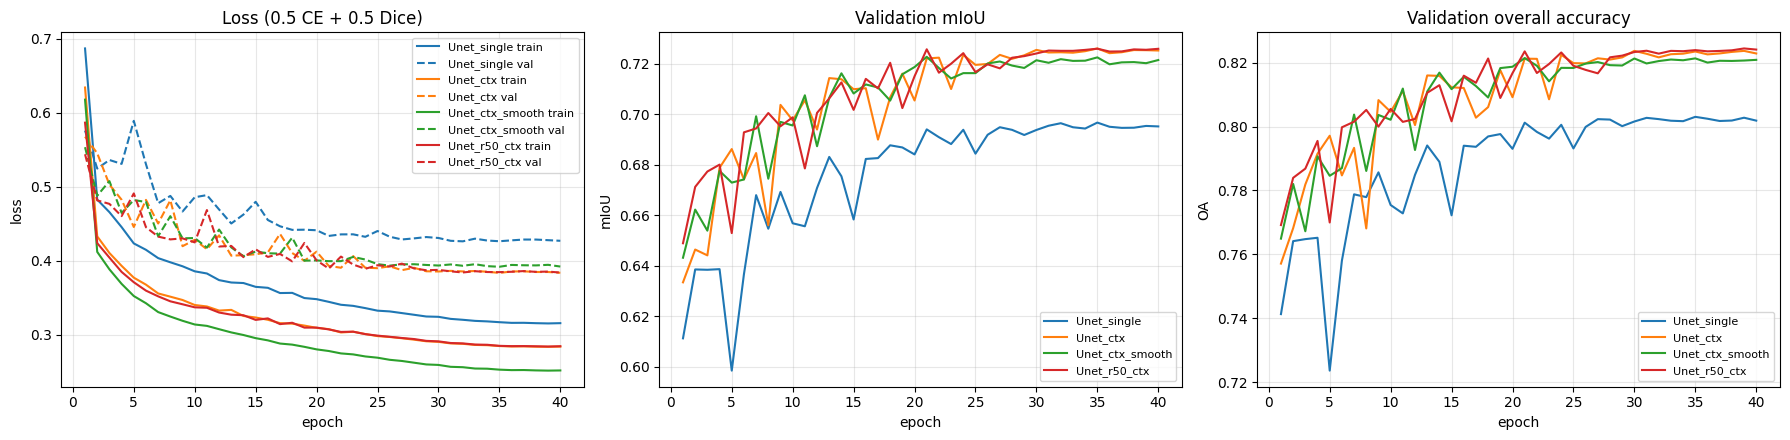

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
    axes[0].plot(h.epoch, h.train_loss, color=color, label=f"{name} train")
    axes[0].plot(h.epoch, h.val_loss, color=color, linestyle="--", label=f"{name} val")
    axes[1].plot(h.epoch, h.val_mIoU, color=color, label=name)
    axes[2].plot(h.epoch, h.val_OA, color=color, label=name)
for ax, title, ylabel in zip(axes, ["Loss (0.5 CE + 0.5 Dice)", "Validation mIoU", "Validation overall accuracy"],
                             ["loss", "mIoU", "OA"]):
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(lc.FIGURE_DIR / "training_curves.png", dpi=150)
plt.show()

## Evaluation
One prediction pass per model over every test, holdout and OOD patch (all years). Per patch, the confusion
matrix against that year's label is stored, so all metrics, bootstrap confidence intervals and per-month /
per-year results come from the same predictions. The best model (by validation mIoU) is additionally
evaluated with test-time augmentation (softmax averaged over 4 flips), as used in the prototype.

In [7]:
best_name = max(best_val, key=best_val.get)
ev = meta[meta.split.isin(["test", "holdout_de", "ood"])].copy()
EVAL_IDX = ev.index.to_numpy()
ev["pos"] = np.arange(len(ev))


@torch.no_grad()
def predict(model, cfg, tta=False):
    """Per-patch confusion matrices (N, C, C) and predicted maps (N, H, W) for all EVAL_IDX patches."""
    model.eval()
    n = lc.NUM_CLASSES
    cms, preds = [], []
    for x, y in Batches(EVAL_IDX, cfg):
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            p = (lc.predict_tta(model, x) if tta else model(x)).argmax(1)
        b = y.shape[0]
        keep = y != lc.IGNORE_INDEX
        patch_idx = torch.arange(b, device=device).view(b, 1, 1).expand_as(y)
        idx = patch_idx[keep] * n * n + y[keep] * n + p[keep]
        cms.append(torch.bincount(idx, minlength=b * n * n).view(b, n, n).cpu().numpy())
        preds.append(p.cpu().numpy().astype(np.uint8))
    return np.concatenate(cms), np.concatenate(preds)


def merge_cm(cm):
    """5-class confusion matrices (..., 5, 5) -> 4 classes (Grassland + Cropland merged), as in v1/v2."""
    m = np.eye(len(lc.CLASS_NAMES_4), dtype=np.int64)[lc.TO_4_CLASSES]          # (5, 4)
    return np.einsum("ji,...jk,kl->...il", m, cm, m)


def metrics_vec(cm):
    """OA and mIoU for a stack of confusion matrices (..., C, C)."""
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(np.float64)
    iou = tp / np.maximum(cm.sum(-1) + cm.sum(-2) - tp, 1)
    return tp.sum(-1) / np.maximum(cm.sum((-1, -2)), 1), iou.mean(-1)


def bootstrap_ci(patch_cms, groups, n_boot=N_BOOTSTRAP):
    """95 % CI of OA and mIoU, resampling whole 5.12 km blocks with replacement."""
    keys, inv = np.unique(groups, return_inverse=True)
    block_cms = np.zeros((len(keys),) + patch_cms.shape[1:], dtype=np.int64)
    np.add.at(block_cms, inv, patch_cms)
    rng = np.random.default_rng(SEED)
    samples = block_cms[rng.integers(0, len(keys), size=(n_boot, len(keys)))].sum(1)
    oa, miou = metrics_vec(samples)
    return np.percentile(oa, [2.5, 97.5]) * 100, np.percentile(miou, [2.5, 97.5]) * 100


def set_mask(split, years, regions=None):
    mask = (ev.split == split) & ev.year.isin(years)
    if regions is not None:
        mask &= ev.region.isin(regions)
    return mask.to_numpy()


def result_row(name, cms, label, mask):
    cms_m = cms[mask]
    m = lc.metrics_from_confusion(cms_m.sum(0))
    (oa_lo, oa_hi), (mi_lo, mi_hi) = bootstrap_ci(cms_m, ev["group"].to_numpy()[mask])
    row = {"model": name, "set": label, "OA (%)": m["OA"] * 100, "OA 95% CI": f"{oa_lo:.1f}–{oa_hi:.1f}",
           "mIoU (%)": m["mIoU"] * 100, "mIoU 95% CI": f"{mi_lo:.1f}–{mi_hi:.1f}",
           "mIoU 4-class (%)": lc.metrics_from_confusion(merge_cm(cms_m.sum(0)))["mIoU"] * 100}
    for c, cname in enumerate(lc.CLASS_NAMES):
        row[f"{cname} IoU"] = m["IoU"][c] * 100
        row[f"{cname} F1"] = m["F1"][c] * 100
    return row


v2_regions = sorted(set(ev.region[ev.split == "test"]) - set(RURAL_REGIONS))
patch_cms, preds = {}, {}
for name in VARIANTS:
    model, cfg = lc.load_checkpoint(lc.MODEL_DIR / f"{name}.pth", device)
    runs = [(name, False)] + ([(f"{name} + TTA", True)] if name == best_name else [])
    for run_name, tta in runs:
        t0 = time.time()
        patch_cms[run_name], preds[run_name] = predict(model, cfg, tta)
        print(f"evaluated {run_name} ({time.time() - t0:.0f}s)")
    del model
    torch.cuda.empty_cache()

results = []
for run_name, cms in patch_cms.items():
    for label, (split, years) in EVAL_SETS.items():
        mask = set_mask(split, years)
        if mask.any():
            results.append(result_row(run_name, cms, label, mask))
    results.append(result_row(run_name, cms, "test 2021 (v2 regions)", set_mask("test", [2021], v2_regions)))
results_df = pd.DataFrame(results).round(2)
results_df.to_csv(lc.FIGURE_DIR / "results.csv", index=False)

print("=========== TEST SET 2021 (same-year labels; 95 % CI: bootstrap over blocks) ===========")
display(results_df[results_df.set == "test 2021"].drop(columns="set"))
print("=========== ALL EVALUATION SETS: mIoU (%) ===========")
display(results_df.pivot(index="model", columns="set", values="mIoU (%)").round(1))
print("=========== Comparison with dataset v2 (4 classes, identical test locations; v2 best: Unet_clean_var "
      "OA 79.1 / mIoU 70.5 on its full test set) ===========")
display(results_df[results_df.set == "test 2021 (v2 regions)"][["model", "OA (%)", "mIoU 4-class (%)", "mIoU (%)"]])
print("Note: sets of years other than 2021 are scored on stable pixels only (the easier ~90 %), so their numbers "
      "are not directly comparable with the 2021 sets.")

evaluated Unet_single (32s)
evaluated Unet_ctx (36s)
evaluated Unet_ctx + TTA (105s)
evaluated Unet_ctx_smooth (37s)
evaluated Unet_r50_ctx (45s)
=========== TEST SET 2021 (same-year labels; 95 % CI: bootstrap over blocks) ===========


,model,OA (%),OA 95% CI,mIoU (%),mIoU 95% CI,mIoU 4-class (%),Forest IoU,Forest F1,Grassland IoU,Grassland F1,Cropland IoU,Cropland F1,Urban IoU,Urban F1,Water IoU,Water F1
0,Unet_single,78.13,76.6–79.7,67.89,65.7–69.6,72.65,63.35,77.57,53.70,69.87,74.92,85.66,59.81,74.85,87.67,93.43
7,Unet_ctx,80.19,78.8–81.7,70.70,68.7–72.2,74.05,65.40,79.08,58.79,74.04,80.02,88.90,61.23,75.95,88.06,93.65
14,Unet_ctx + TTA,80.44,79.0–81.9,71.01,69.1–72.5,74.25,65.71,79.31,59.30,74.45,80.47,89.18,61.52,76.18,88.07,93.66
21,Unet_ctx_smooth,80.19,78.8–81.6,70.70,68.8–72.2,73.97,65.63,79.25,59.08,74.28,80.02,88.90,60.58,75.45,88.18,93.72
28,Unet_r50_ctx,80.39,79.0–81.8,71.00,69.2–72.5,74.21,65.56,79.20,59.33,74.47,80.53,89.22,61.44,76.12,88.15,93.70


=========== ALL EVALUATION SETS: mIoU (%) ===========


set,holdout_de 2021,holdout_de 2024–25,ood 2021,ood 2024–25,test 2020–23,test 2021,test 2021 (v2 regions)
model,,,,,,,
Unet_ctx,68.2,72.6,55.6,58.2,73.5,70.7,68.1
Unet_ctx + TTA,68.5,73.0,56.0,58.4,73.8,71.0,68.5
Unet_ctx_smooth,68.1,72.6,57.2,59.5,73.5,70.7,68.0
Unet_r50_ctx,68.2,72.7,55.9,58.5,73.8,71.0,68.4
Unet_single,64.6,69.7,52.7,54.3,70.7,67.9,65.3


=========== Comparison with dataset v2 (4 classes, identical test locations; v2 best: Unet_clean_var OA 79.1 / mIoU 70.5 on its full test set) ===========


,model,OA (%),mIoU 4-class (%),mIoU (%)
6,Unet_single,76.30,70.51,65.29
13,Unet_ctx,78.14,71.88,68.12
20,Unet_ctx + TTA,78.40,72.10,68.48
27,Unet_ctx_smooth,78.11,71.86,68.01
34,Unet_r50_ctx,78.31,72.06,68.35


Note: sets of years other than 2021 are scored on stable pixels only (the easier ~90 %), so their numbers are not directly comparable with the 2021 sets.


## Best model → prototype
Chosen by **validation** mIoU (not test), then copied to `models/best_model.pth` for `app.py`.
Variants whose test confidence intervals overlap should be treated as equivalent.

In [8]:
ckpt = torch.load(lc.MODEL_DIR / f"{best_name}.pth", map_location="cpu", weights_only=False)
torch.save(ckpt, lc.BEST_MODEL_PATH)
best_run = f"{best_name} + TTA"
print(f"Best variant: {best_name} (val mIoU {best_val[best_name]:.4f}, epoch {ckpt['epoch']}) -> {lc.BEST_MODEL_PATH}")
print("The prototype uses it with test-time augmentation; the analyses below use the same setting.")

Best variant: Unet_ctx (val mIoU 0.7260, epoch 35) -> /home/jovyan/vault/deep_learning/models/best_model.pth
The prototype uses it with test-time augmentation; the analyses below use the same setting.


## Confusion matrices (best model + TTA, 2021, row-normalised: % of each true class)
SAR-specific confusions to look for: urban ↔ forest (both bright: double-bounce vs. volume scattering),
grassland ↔ cropland (both low vegetation; they differ mainly in their seasonal course), smooth
fields/tarmac ↔ water (both specular, dark), forest ↔ cropland in leaf-off months.

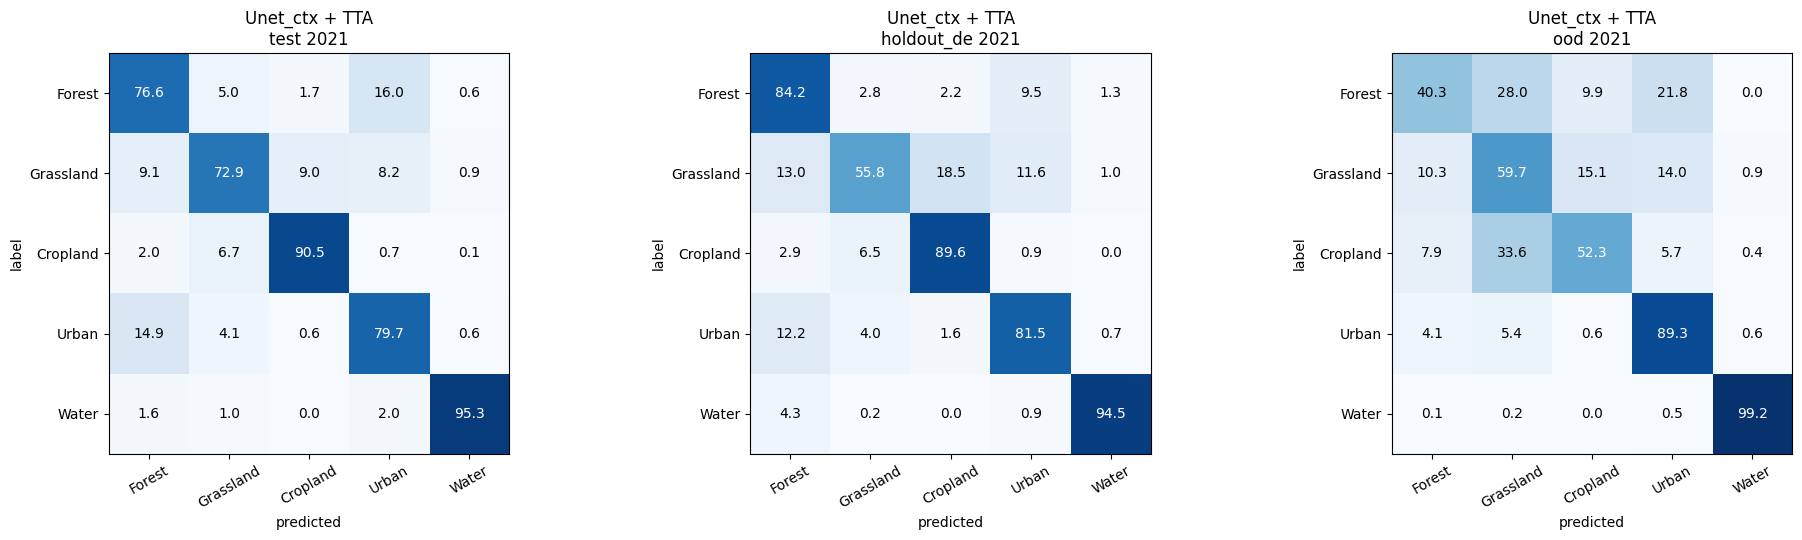

In [9]:
cm_sets = ["test 2021", "holdout_de 2021", "ood 2021"]
fig, axes = plt.subplots(1, len(cm_sets), figsize=(6.5 * len(cm_sets), 5.5))
for ax, label in zip(axes, cm_sets):
    cm = patch_cms[best_run][set_mask(*EVAL_SETS[label])].sum(0)
    cm_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(lc.NUM_CLASSES):
        for j in range(lc.NUM_CLASSES):
            ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center",
                    color="white" if cm_pct[i, j] > 50 else "black")
    ax.set_xticks(range(lc.NUM_CLASSES), lc.CLASS_NAMES, rotation=30)
    ax.set_yticks(range(lc.NUM_CLASSES), lc.CLASS_NAMES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("label")
    ax.set_title(f"{best_run}\n{label}")
plt.tight_layout()
plt.savefig(lc.FIGURE_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## Seasonal and inter-annual effects
The labels are fixed, so any variation over months or years is caused by the changing SAR signal (or by
the satellites: 2024 is Sentinel-1A only, 2025 adds Sentinel-1C).

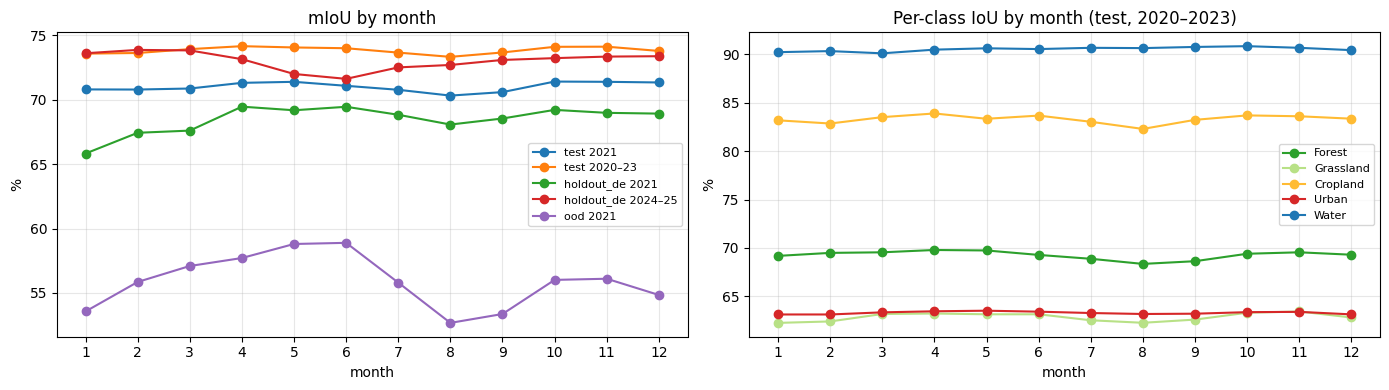

mIoU (%) by imagery year. 2021: full labels; other years: stable pixels only.


split,holdout_de,ood,test
year,,,
2020,73.8,58.4,75.3
2021,68.5,56.0,71.0
2022,74.0,59.6,74.7
2023,73.5,58.5,74.6
2024,72.8,58.8,NaN
2025,73.3,58.1,NaN


In [10]:
cms = patch_cms[best_run]
month_rows = []
for label in ["test 2021", "test 2020–23", "holdout_de 2021", "holdout_de 2024–25", "ood 2021"]:
    mask = set_mask(*EVAL_SETS[label])
    for month in range(1, 13):
        m = lc.metrics_from_confusion(cms[mask & (ev.month == month).to_numpy()].sum(0))
        month_rows.append({"set": label, "month": month, "OA": m["OA"] * 100, "mIoU": m["mIoU"] * 100,
                           **{f"{n} IoU": m["IoU"][c] * 100 for c, n in enumerate(lc.CLASS_NAMES)}})
monthly_df = pd.DataFrame(month_rows).round(2)
monthly_df.to_csv(lc.FIGURE_DIR / "accuracy_by_month.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for label in monthly_df.set.unique():
    d = monthly_df[monthly_df.set == label]
    axes[0].plot(d.month, d.mIoU, marker="o", label=label)
d = monthly_df[monthly_df.set == "test 2020–23"]
for n, color in zip(lc.CLASS_NAMES, lc.CLASS_COLORS):
    axes[1].plot(d.month, d[f"{n} IoU"], marker="o", color=color, label=n)
axes[0].set_title("mIoU by month")
axes[1].set_title("Per-class IoU by month (test, 2020–2023)")
for ax in axes:
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("month")
    ax.set_ylabel("%")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(lc.FIGURE_DIR / "accuracy_by_month.png", dpi=150)
plt.show()

year_rows = []
for split in ["test", "holdout_de", "ood"]:
    for year in sorted(ev.year[ev.split == split].unique()):
        m = lc.metrics_from_confusion(cms[set_mask(split, [year])].sum(0))
        year_rows.append({"split": split, "year": year, "mIoU": m["mIoU"] * 100})
by_year = pd.DataFrame(year_rows).pivot(index="year", columns="split", values="mIoU").round(1)
by_year.to_csv(lc.FIGURE_DIR / "accuracy_by_year.csv")
print("mIoU (%) by imagery year. 2021: full labels; other years: stable pixels only.")
by_year

## How classification errors inflate change percentages
Every location has 12 monthly images per year but **one** label, so the true change is ~0 pp. Running
the prototype's change calculation on these predictions measures the *apparent* change that comes purely
from classification errors: the noise floor below which changes reported by the prototype cannot be
trusted. Computed for every variant, so the effect of temporal context on stability is visible.

In [11]:
def change_stats(run_name, split, year):
    p_all = preds[run_name]
    rows = []
    df = ev[(ev.split == split) & (ev.year == year)]
    for _, loc in df.groupby("loc"):
        if len(loc) < 12:            # only complete time series
            continue
        loc = loc.sort_values("month")
        p = p_all[loc.pos.to_numpy()].copy()
        unlabelled = np.any([lc.labels_from_raw(MASKS[i], year=year) == lc.IGNORE_INDEX for i in loc.index], axis=0)
        p[:, unlabelled] = lc.IGNORE_INDEX           # same pixel set in every month
        pct = np.stack([lc.class_percentages(q) for q in p])          # (months, classes)
        flips = [((a != b) & (a != lc.IGNORE_INDEX)).sum() / max((a != lc.IGNORE_INDEX).sum(), 1) * 100
                 for a, b in zip(p[:-1], p[1:])]
        rows.append({**{f"{n} |m2m| pp": np.abs(np.diff(pct[:, c])).mean() for c, n in enumerate(lc.CLASS_NAMES)},
                     **{f"{n} |first→last| pp": abs(pct[-1, c] - pct[0, c]) for c, n in enumerate(lc.CLASS_NAMES)},
                     **{f"{n} range pp": pct[:, c].max() - pct[:, c].min() for c, n in enumerate(lc.CLASS_NAMES)},
                     "mean class |m2m| pp": np.abs(np.diff(pct, axis=0)).mean(),
                     "pixels changing class per month (%)": np.mean(flips)})
    return pd.DataFrame(rows).mean()


change_sets = [("test", 2021), ("holdout_de", 2021), ("holdout_de", 2025), ("ood", 2021)]
change = {(run, f"{s} {y}"): change_stats(run, s, y) for run in preds for s, y in change_sets}
change_df = pd.DataFrame(change).T
change_df.index.names = ["model", "set"]
change_df.round(2).to_csv(lc.FIGURE_DIR / "spurious_change.csv")
print("Pixels changing class per month (%) — lower is more stable (true change ≈ 0):")
display(change_df["pixels changing class per month (%)"].unstack().round(2))
print("Mean absolute month-to-month change of the class shares (pp):")
display(change_df["mean class |m2m| pp"].unstack().round(2))
print(f"Per-class detail for {best_run}:")
change_df.loc[best_run].T.round(2)

Pixels changing class per month (%) — lower is more stable (true change ≈ 0):


set,holdout_de 2021,holdout_de 2025,ood 2021,test 2021
model,,,,
Unet_ctx,6.91,5.21,10.32,6.36
Unet_ctx + TTA,6.29,4.69,9.68,5.77
Unet_ctx_smooth,6.38,4.98,10.18,6.17
Unet_r50_ctx,6.85,5.22,9.99,6.39
Unet_single,13.52,9.81,15.40,11.77


Mean absolute month-to-month change of the class shares (pp):


set,holdout_de 2021,holdout_de 2025,ood 2021,test 2021
model,,,,
Unet_ctx,0.90,0.70,2.24,0.84
Unet_ctx + TTA,0.81,0.65,2.18,0.75
Unet_ctx_smooth,0.89,0.73,2.28,0.92
Unet_r50_ctx,0.86,0.67,2.00,0.84
Unet_single,2.07,1.38,2.95,1.61


Per-class detail for Unet_ctx + TTA:


set,test 2021,holdout_de 2021,holdout_de 2025,ood 2021
Forest |m2m| pp,1.14,1.14,0.76,2.29
Grassland |m2m| pp,0.98,1.07,0.97,3.52
Cropland |m2m| pp,0.74,1.09,0.91,4.10
Urban |m2m| pp,0.82,0.68,0.56,0.76
Water |m2m| pp,0.08,0.09,0.06,0.23
Forest |first→last| pp,2.04,3.05,1.23,1.89
Grassland |first→last| pp,1.99,1.67,1.31,3.69
Cropland |first→last| pp,1.30,2.47,1.34,3.59
Urban |first→last| pp,1.43,2.10,1.02,0.99
Water |first→last| pp,0.18,0.18,0.17,0.54


## Qualitative examples (test set, 2021)

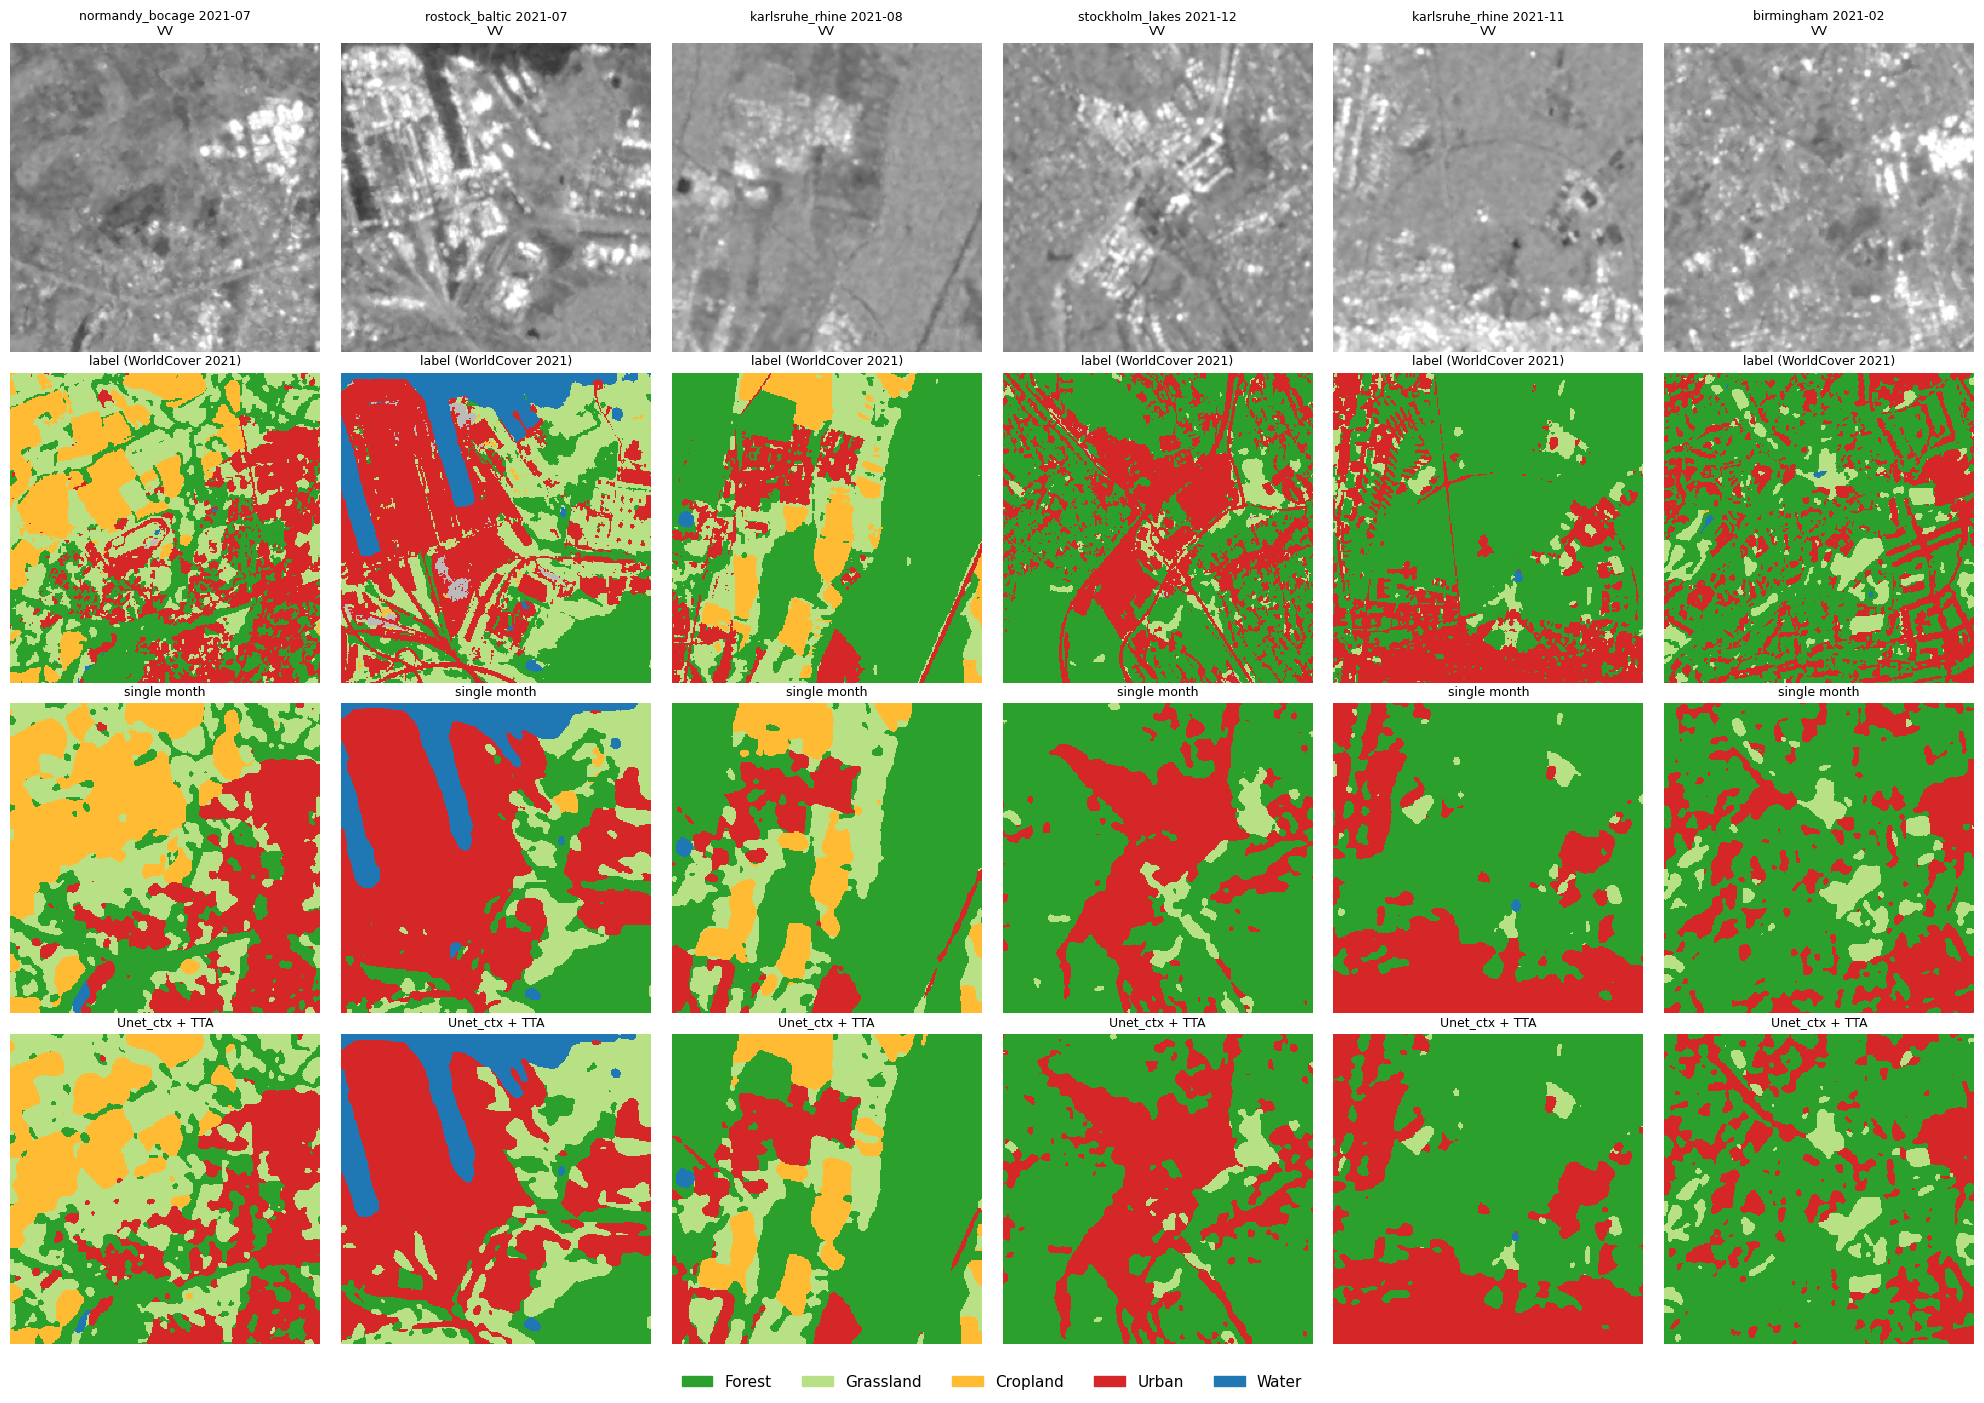

In [12]:
lmap = ListedColormap(lc.CLASS_COLORS)
lmap.set_bad("#bbbbbb")
rng = np.random.default_rng(SEED)
pool = ev[(ev.split == "test") & (ev.year == 2021)]
pick = pool.iloc[rng.choice(len(pool), 6, replace=False)]
show = [("Unet_single", "single month"), (best_run, best_run)]
fig, axes = plt.subplots(2 + len(show), 6, figsize=(20, 14))
for i, (idx, r) in enumerate(pick.iterrows()):
    axes[0, i].imshow(IMAGES[idx, 0].astype(np.float32), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"{r['region']} {r['year']}-{r['month']:02d}\nVV", fontsize=9)
    axes[1, i].imshow(np.ma.masked_equal(lc.labels_from_raw(MASKS[idx]), lc.IGNORE_INDEX), cmap=lmap, vmin=0,
                      vmax=lc.NUM_CLASSES - 1, interpolation="nearest")
    axes[1, i].set_title("label (WorldCover 2021)", fontsize=9)
    for row, (run, title) in enumerate(show, start=2):
        axes[row, i].imshow(preds[run][r["pos"]], cmap=lmap, vmin=0, vmax=lc.NUM_CLASSES - 1,
                            interpolation="nearest")
        axes[row, i].set_title(title, fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=[Patch(color=c, label=n) for c, n in zip(lc.CLASS_COLORS, lc.CLASS_NAMES)],
           loc="lower center", ncol=lc.NUM_CLASSES, frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(lc.FIGURE_DIR / "qualitative_examples.png", dpi=110)
plt.show()